In [ ]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import inspect
import numpy.linalg as la

import numpy as np
import matplotlib.pyplot as plt
import scipy
import pandas as pd
import matplotlib.gridspec as gs
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 20
})

from scipy.optimize import minimize
from scipy.optimize import least_squares
import itertools
from joblib import Parallel, delayed
import multiprocessing

import os

os.environ["XLA_FLAGS"] = (
    "--xla_cpu_multi_thread_eigen=true "
    "intra_op_parallelism_threads=32"
)

import time

## Setup

### Cavity 1

In [6]:
f=np.logspace(-3, 3, 1000)
rinum=0.98
renum=0.99
lnum=1e-5
tinum=np.sqrt(1-rinum**2-lnum)
tenum=np.sqrt(1-renum**2-lnum)
fmnum=20e6
wm=2*np.pi*fmnum
dLnum=10.6
Lnum=1e5+dLnum
# difference from the resonance
dfnum1=25
dfnum2=30
dwnum1=2*np.pi*dfnum1
dwnum2=2*np.pi*dfnum2
c=scipy.constants.c
Tcnum=Lnum/scipy.constants.c
a00num=100.
a01num=1.
params1=[a00num, a01num, a00num, a01num, dwnum1, dwnum2, rinum, renum, tinum, tenum, Tcnum]

### Cavity 2

In [7]:
rinum=0.984
renum=0.989
lnum=1e-5
tinum=np.sqrt(1-rinum**2-lnum)
tenum=np.sqrt(1-renum**2-lnum)
fmnum=20e6
wm=2*np.pi*fmnum
dLnum=10.2
Lnum=1e5+dLnum
# difference from the resonance
dfnum1=22
dfnum2=27
dwnum1=2*np.pi*dfnum1
dwnum2=2*np.pi*dfnum2
c=scipy.constants.c
Tcnum=Lnum/scipy.constants.c
a00num=100.
a01num=1.
params2=[a00num, a01num, a00num, a01num, dwnum1, dwnum2 , rinum, renum, tinum, tenum, Tcnum]

### Cavity 3

In [8]:
rinum=0.99
renum=0.98
lnum=1e-5
tinum=np.sqrt(1-rinum**2-lnum)
tenum=np.sqrt(1-renum**2-lnum)
fmnum=20e6
wm=2*np.pi*fmnum
dLnum=10.4
Lnum=1e5+dLnum
# difference from the resonance
dfnum1=27
dfnum2=21
dwnum1=2*np.pi*dfnum1
dwnum2=2*np.pi*dfnum2
c=scipy.constants.c
Tcnum=Lnum/scipy.constants.c
a00num=100.
a01num=1.
params3=[a00num, a01num, a00num, a01num, dwnum1, dwnum2, rinum, renum, tinum, tenum, Tcnum]

## PDH response

In [ ]:
@jax.jit
def pdh_com_stable(f, a, dw, wb, wc, ri, re, ti, Tc):
    w = 2 * jnp.pi * f

    exp_dw = jnp.exp(-2j * dw * Tc)
    exp_w  = jnp.exp(-2j * w * Tc)

    # ===== gamma =====
    cos_term = jnp.cos(2 * wb * Tc)

    numg = (cos_term - ri * re * exp_dw) * exp_dw

    e1 = jnp.exp(-2j * (dw + wb) * Tc)
    e2 = jnp.exp(-2j * (dw - wb) * Tc)

    deng = (1 - ri * re * e1) * (1 - ri * re * e2)

    gamma = numg / deng

    # ===== A =====
    tmp = (re / ri) * ti**2 * gamma

    A = jnp.real(1 - tmp)

    term1 = -4 * ri**2 * A

    # ===== term2 =====
    exp_wc = jnp.exp(2j * (dw + wc) * Tc)

    B = 1 - tmp

    num = jnp.real(exp_wc * B) - ri * re * A * exp_w

    e3 = jnp.exp(2j * (dw + wc - w) * Tc)
    e4 = jnp.exp(-2j * (dw + wc + w) * Tc)

    den = (1 - ri * re * e3) * (1 - ri * re * e4)

    term2 = 4 * ri * re * ti**2 * exp_w * num / den

    out = a * (term1 + term2) / (1j * f)

    return out

In [10]:
# One direction
@jax.jit
def pdh_fun_jax1(f, params):
    a00, a01, a002, a012, dw1, dw2, ri, re, ti, te, Tc = params

    return (
        pdh_com_stable(f, -a00, 0.0, wm, 0.0, ri, re, ti, Tc) + pdh_com_stable(f,  a00, 0.0, 0.0, wm, ri, re, ti, Tc) +
        pdh_com_stable(f, -a01, dw1,  wm, 0.0, ri, re, ti, Tc) + 0.5 * pdh_com_stable(f, a01, dw1, 0.0,  wm, ri, re, ti, Tc) + 0.5 * pdh_com_stable(f, a01, dw1, 0.0, -wm, ri, re, ti, Tc))

# Another direction
@jax.jit
def pdh_fun_jax2(f, params):
    a00, a01, a002, a012, dw1, dw2, re, ri, te, ti, Tc = params

    return (
        pdh_com_stable(f, -a002, 0.0, wm, 0.0, ri, re, ti, Tc) + pdh_com_stable(f,  a002, 0.0, 0.0, wm, ri, re, ti, Tc) +
        pdh_com_stable(f, -a012, dw2,  wm, 0.0, ri, re, ti, Tc) + 0.5 * pdh_com_stable(f, a012, dw2, 0.0,  wm, ri, re, ti, Tc) + 0.5 * pdh_com_stable(f, a012, dw2, 0.0, -wm, ri, re, ti, Tc))

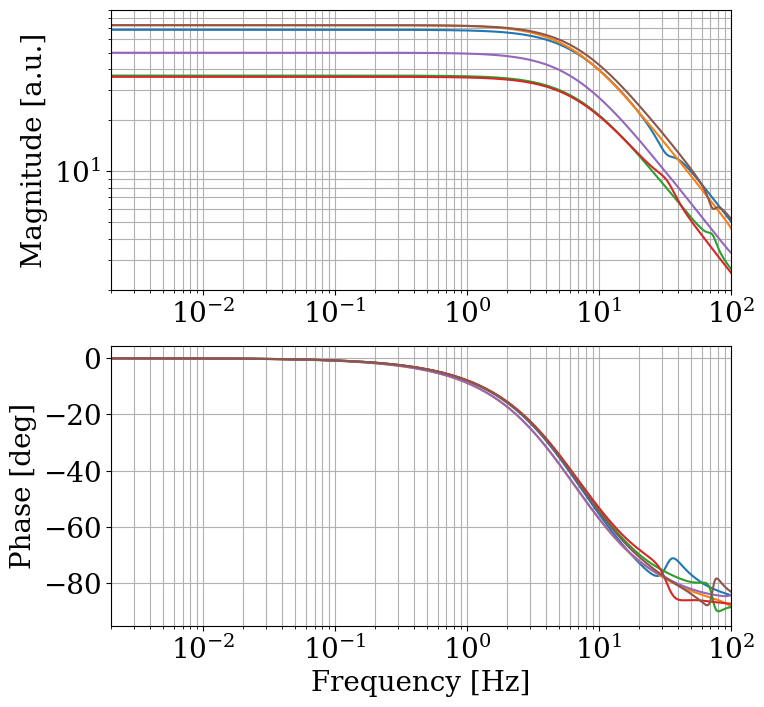

In [ ]:
fig=plt.figure(figsize=(8,8))

GS=gs.GridSpec(2,1)
ax1=plt.subplot(GS[0])
ax2=plt.subplot(GS[1])

ax1.loglog(f,abs(pdh_fun_jax1(f, params1)))
ax1.loglog(f,abs(pdh_fun_jax1(f, params2)))
ax1.loglog(f,abs(pdh_fun_jax1(f, params3)))
ax1.loglog(f,abs(pdh_fun_jax2(f, params1)))
ax1.loglog(f,abs(pdh_fun_jax2(f, params2)))
ax1.loglog(f,abs(pdh_fun_jax2(f, params3)))
ax1.grid(which='both')
ax1.set_ylabel('Magnitude [a.u.]')
ax1.set_xlim(2e-3, 1e2)
ax1.set_ylim(2, 90)

ax2.semilogx(f, np.angle(pdh_fun_jax1(f, params1),deg=True))
ax2.semilogx(f, np.angle(pdh_fun_jax1(f, params2),deg=True))
ax2.semilogx(f, np.angle(pdh_fun_jax1(f, params3),deg=True))
ax2.semilogx(f, np.angle(pdh_fun_jax2(f, params1),deg=True))
ax2.semilogx(f, np.angle(pdh_fun_jax2(f, params2),deg=True))
ax2.semilogx(f, np.angle(pdh_fun_jax2(f, params3),deg=True))
ax2.grid(which='both')
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel('Phase [deg]')
#ax2.set_yticks([-180,-90,0,90,180])
#ax2.set_ylim([-180,180])
ax2.set_xlim(2e-3, 1e2)

## Search optimal point

## Derivation of null

In [11]:
# Noise of DECIGO
def DECIGO(f):
    return jnp.sqrt(8e-25**2+5e-51*f**(-4)+1.2e-50*f**2)

# Noise of BLFPI
def BLFPI(f):
    return jnp.sqrt(7e-23**2+1.2e-46*f**(-4)+2.25e-46*f**2)

def Ne1(f, params):
    f = jnp.atleast_1d(f)
    return jnp.ones_like(f) * (7e-23 / jnp.sqrt(2)) * jnp.abs(pdh_fun_jax1(f, params))[0]

def Ne2(f, params):
    f = jnp.atleast_1d(f)
    return jnp.ones_like(f) * (7e-23 / jnp.sqrt(2)) * jnp.abs(pdh_fun_jax2(f, params))[0]

# Suppressed Laser frequency noise
def fnoise(f):
    return 0.1*f**(-1)*1e-4/6e14

## Search optimal point

## Below FSR

In [12]:
# measurement time [s]
Tbfsr=1000
# sampling frequency [Hz]
fsbfsr=20
Freqbfsr=np.linspace(1/Tbfsr, fsbfsr/2, int(fsbfsr/2/(1/Tbfsr)))
fcut=0.1

mask = Freqbfsr <= fcut
freqbfsr = jnp.asarray(Freqbfsr[mask])
dfreqbfsr = freqbfsr[1] - freqbfsr[0]

In [13]:
def nullbFSR1(params):

  pdh_values = pdh_fun_jax1(freqbfsr, params)

  # Reverting to the more comprehensive null function that incorporates noise
  # This form aims to minimize the combined effect of signal error and noise.
  term_numerator_signal = jnp.abs(1 - Sbfsr / pdh_values)**2*fnoise(freqbfsr)**2
  term_noise_contribution =Ne1(freqbfsr, params)**2/jnp.abs(pdh_values)**2

  NULL_array = (term_numerator_signal + term_noise_contribution) *dfreqbfsr
  return (jnp.sum(NULL_array))

def nullbFSR2(params):

  pdh_values = pdh_fun_jax2(freqbfsr, params)

  # Reverting to the more comprehensive null function that incorporates noise
  # This form aims to minimize the combined effect of signal error and noise.
  term_numerator_signal = jnp.abs(1 - Sbfsr / pdh_values)**2*fnoise(freqbfsr)**2
  term_noise_contribution =Ne2(freqbfsr, params)**2/jnp.abs(pdh_values)**2

  NULL_array = (term_numerator_signal + term_noise_contribution) *dfreqbfsr
  return (jnp.sum(NULL_array))

original_params_jax = jnp.array(params1, dtype=jnp.float64)
params_jax_for_S = jnp.array(params1, dtype=jnp.float64)
Sbfsr = pdh_fun_jax1(freqbfsr, params_jax_for_S)
init_res=5e-43

In [ ]:
# =========================
# parameter setting
# =========================
Nset = 3
Nparam = 11

Ncoord = 1000
Ncoord_coarse = 10

Nparallel = 20
Ntrial = 10

COARSE_COST_THRESHOLD = 5e41

log_mask = jnp.array([True] * Nparam)

# =========================
# parameter transform
# =========================
@jax.jit
def to_physical(x):

    x = x.reshape(Nset, Nparam)

    return jnp.where(
        log_mask[None, :],
        jnp.exp(x),
        x
    )

@jax.jit
def to_raw(p):

    return jnp.where(
        log_mask[None, :],
        jnp.log(p),
        p
    ).reshape(-1)

# =========================
# precompute true PDH
# =========================
P11_TRUE = pdh_fun_jax1(
    freqbfsr,
    params1
)

P12_TRUE = pdh_fun_jax2(
    freqbfsr,
    params1
)

P21_TRUE = pdh_fun_jax1(
    freqbfsr,
    params2
)

P22_TRUE = pdh_fun_jax2(
    freqbfsr,
    params2
)

P31_TRUE = pdh_fun_jax1(
    freqbfsr,
    params3
)

P32_TRUE = pdh_fun_jax2(
    freqbfsr,
    params3
)

# =========================
# Rayleigh noise
# =========================
@jax.jit
def sample_rayleigh_from_asd(asd, key):

    sigma = asd / jnp.sqrt(jnp.pi / 2)

    key, subkey = jax.random.split(key)

    samples = jax.random.rayleigh(
        subkey,
        scale=sigma,
        shape=asd.shape
    )

    return samples, key

# =========================
# noise generation
# =========================
@jax.jit
def generate_noise(key):

    fnoise_sample1, key = sample_rayleigh_from_asd(
        fnoise(Freqbfsr),
        key
    )

    fnoise_sample2, key = sample_rayleigh_from_asd(
        fnoise(Freqbfsr),
        key
    )

    fnoise_sample3, key = sample_rayleigh_from_asd(
        fnoise(Freqbfsr),
        key
    )

    fnoise_sample4, key = sample_rayleigh_from_asd(
        fnoise(Freqbfsr),
        key
    )

    fnoise_sample5, key = sample_rayleigh_from_asd(
        fnoise(Freqbfsr),
        key
    )

    fnoise_sample6, key = sample_rayleigh_from_asd(
        fnoise(Freqbfsr),
        key
    )

    Ne_sample1, key = sample_rayleigh_from_asd(
        Ne1(Freqbfsr, params1),
        key
    )

    Ne_sample2, key = sample_rayleigh_from_asd(
        Ne2(Freqbfsr, params1),
        key
    )

    Ne_sample3, key = sample_rayleigh_from_asd(
        Ne1(Freqbfsr, params2),
        key
    )

    Ne_sample4, key = sample_rayleigh_from_asd(
        Ne2(Freqbfsr, params2),
        key
    )

    Ne_sample5, key = sample_rayleigh_from_asd(
        Ne1(Freqbfsr, params3),
        key
    )

    Ne_sample6, key = sample_rayleigh_from_asd(
        Ne2(Freqbfsr, params3),
        key
    )

    beat_sample1, key = sample_rayleigh_from_asd(
        1.5e-23 * Freqbfsr,
        key
    )

    beat_sample2, key = sample_rayleigh_from_asd(
        1.5e-23 * Freqbfsr,
        key
    )

    beat_sample3, key = sample_rayleigh_from_asd(
        1.5e-23 * Freqbfsr,
        key
    )

    return (

        fnoise_sample1,
        fnoise_sample2,
        fnoise_sample3,

        fnoise_sample4,
        fnoise_sample5,
        fnoise_sample6,

        Ne_sample1,
        Ne_sample2,
        Ne_sample3,

        Ne_sample4,
        Ne_sample5,
        Ne_sample6,

        beat_sample1,
        beat_sample2,
        beat_sample3,

        key
    )

# =========================
# residual
# =========================
@jax.jit
def residuals_jax(
    x,

    fnoise_sample1,
    fnoise_sample2,
    fnoise_sample3,

    fnoise_sample4,
    fnoise_sample5,
    fnoise_sample6,

    Ne_sample1,
    Ne_sample2,
    Ne_sample3,

    Ne_sample4,
    Ne_sample5,
    Ne_sample6,

    beat_sample1,
    beat_sample2,
    beat_sample3
):

    p = to_physical(x)

    x1 = p[0]
    x2 = p[1]
    x3 = p[2]

    # =========================
    # model PDH
    # =========================
    p11 = pdh_fun_jax1(
        freqbfsr,
        x1
    )

    p12 = pdh_fun_jax2(
        freqbfsr,
        x1
    )

    p21 = pdh_fun_jax1(
        freqbfsr,
        x2
    )

    p22 = pdh_fun_jax2(
        freqbfsr,
        x2
    )

    p31 = pdh_fun_jax1(
        freqbfsr,
        x3
    )

    p32 = pdh_fun_jax2(
        freqbfsr,
        x3
    )

    # =========================
    # response noise
    # =========================
    rn1 = (
        1 - P11_TRUE / p11
    ) * fnoise_sample1

    rn2 = (
        1 - P12_TRUE / p12
    ) * fnoise_sample2

    rn3 = (
        1 - P21_TRUE / p21
    ) * fnoise_sample3

    rn4 = (
        1 - P22_TRUE / p22
    ) * fnoise_sample4

    rn5 = (
        1 - P31_TRUE / p31
    ) * fnoise_sample5

    rn6 = (
        1 - P32_TRUE / p32
    ) * fnoise_sample6

    # =========================
    # early real/imag split
    # =========================
    rn1_real = jnp.real(rn1)
    rn1_imag = jnp.imag(rn1)

    rn2_real = jnp.real(rn2)
    rn2_imag = jnp.imag(rn2)

    rn3_real = jnp.real(rn3)
    rn3_imag = jnp.imag(rn3)

    rn4_real = jnp.real(rn4)
    rn4_imag = jnp.imag(rn4)

    rn5_real = jnp.real(rn5)
    rn5_imag = jnp.imag(rn5)

    rn6_real = jnp.real(rn6)
    rn6_imag = jnp.imag(rn6)

    # =========================
    # manual abs
    # =========================
    abs_p11 = jnp.sqrt(
        jnp.real(p11)**2
        + jnp.imag(p11)**2
    )

    abs_p12 = jnp.sqrt(
        jnp.real(p12)**2
        + jnp.imag(p12)**2
    )

    abs_p21 = jnp.sqrt(
        jnp.real(p21)**2
        + jnp.imag(p21)**2
    )

    abs_p22 = jnp.sqrt(
        jnp.real(p22)**2
        + jnp.imag(p22)**2
    )

    abs_p31 = jnp.sqrt(
        jnp.real(p31)**2
        + jnp.imag(p31)**2
    )

    abs_p32 = jnp.sqrt(
        jnp.real(p32)**2
        + jnp.imag(p32)**2
    )

    # =========================
    # electronics noise
    # =========================
    re1 = Ne_sample1 / abs_p11

    re2 = Ne_sample2 / abs_p12

    re3 = Ne_sample3 / abs_p21

    re4 = Ne_sample4 / abs_p22

    re5 = Ne_sample5 / abs_p31

    re6 = Ne_sample6 / abs_p32

    # =========================
    # concatenate
    # =========================
    res = jnp.concatenate([

        rn1_real,
        rn1_imag,

        rn2_real,
        rn2_imag,

        rn3_real,
        rn3_imag,

        rn4_real,
        rn4_imag,

        rn5_real,
        rn5_imag,

        rn6_real,
        rn6_imag,

        re1,
        re2,
        re3,
        re4,
        re5,
        re6,

        beat_sample1,
        beat_sample2,
        beat_sample3
    ])

    return (
        res
        * jnp.sqrt(dfreqbfsr)
        / init_res
    )
# =========================
# jacobian
# =========================
jacobian_jax = jax.jit(
    jax.jacfwd(residuals_jax)
)

# =========================
# wrappers
# =========================
def make_wrappers(

    fnoise_sample1,
    fnoise_sample2,
    fnoise_sample3,

    fnoise_sample4,
    fnoise_sample5,
    fnoise_sample6,

    Ne_sample1,
    Ne_sample2,
    Ne_sample3,

    Ne_sample4,
    Ne_sample5,
    Ne_sample6,

    beat_sample1,
    beat_sample2,
    beat_sample3
):

    def residuals_np(x):

        return np.asarray(

            residuals_jax(
                x,

                fnoise_sample1,
                fnoise_sample2,
                fnoise_sample3,

                fnoise_sample4,
                fnoise_sample5,
                fnoise_sample6,

                Ne_sample1,
                Ne_sample2,
                Ne_sample3,

                Ne_sample4,
                Ne_sample5,
                Ne_sample6,

                beat_sample1,
                beat_sample2,
                beat_sample3
            ),

            dtype=np.float64
        )

    def jacobian_np(x):

        return np.asarray(

            jacobian_jax(
                x,

                fnoise_sample1,
                fnoise_sample2,
                fnoise_sample3,

                fnoise_sample4,
                fnoise_sample5,
                fnoise_sample6,

                Ne_sample1,
                Ne_sample2,
                Ne_sample3,

                Ne_sample4,
                Ne_sample5,
                Ne_sample6,

                beat_sample1,
                beat_sample2,
                beat_sample3
            ),

            dtype=np.float64
        )

    return residuals_np, jacobian_np

# =========================
# block wrapper
# =========================
def make_block_wrapper(
    residuals_np_full,
    jacobian_np_full,
    x_fixed,
    block_id,
    work_array
):

    start = block_id * Nparam
    end = start + Nparam

    def residuals_block(x_block):

        work_array[:] = x_fixed
        work_array[start:end] = x_block

        return residuals_np_full(work_array)

    def jacobian_block(x_block):

        work_array[:] = x_fixed
        work_array[start:end] = x_block

        J = jacobian_np_full(work_array)

        return J[:, start:end]

    return residuals_block, jacobian_block

# =========================
# single optimization
# =========================
def run_single_opt(
    x0,
    residuals_np,
    jacobian_np,
    bounds
):

    return least_squares(
        fun=residuals_np,
        x0=x0,
        jac=jacobian_np,
        bounds=bounds,
        method="trf",
        x_scale='jac',
        ftol=1e-15,
        xtol=1e-15,
        gtol=1e-15,
        max_nfev=10,
        verbose=0
    )

# =========================
# one chain
# =========================
def run_chain(
    chain_id,
    true_params,
    bounds,
    bounds_blocks,
    residuals_np_full,
    jacobian_np_full
):

    print(f"chain {chain_id} start")

    try:

        init_noise = 0.01 * np.random.randn(
            Nset,
            Nparam
        )

        init_params = (
            np.asarray(true_params)
            * np.exp(init_noise)
        )

        x_init = np.array(
            np.asarray(
                to_raw(
                    jnp.array(init_params)
                )
            ),
            dtype=np.float64
        )

        lower_bounds = bounds[0]
        upper_bounds = bounds[1]

        eps = 1e-12

        x_init = np.clip(
            x_init,
            lower_bounds + eps,
            upper_bounds - eps
        )

        x_current = np.array(
            x_init,
            dtype=np.float64,
            copy=True
        )

        work_array = np.empty_like(
            x_current
        )

        block_wrappers = []

        for block_id in range(Nset):

            block_wrappers.append(

                make_block_wrapper(
                    residuals_np_full,
                    jacobian_np_full,
                    x_current,
                    block_id,
                    work_array
                )
            )

        # =========================
        # coarse optimization
        # =========================
        for coord_iter in range(
            Ncoord_coarse
        ):

            for block_id in range(Nset):

                start = (
                    block_id
                    * Nparam
                )

                end = start + Nparam

                residuals_block, jacobian_block = (
                    block_wrappers[block_id]
                )

                x0_block = x_current[
                    start:end
                ]

                result = run_single_opt(
                    x0_block,
                    residuals_block,
                    jacobian_block,
                    bounds_blocks[block_id]
                )

                x_current[start:end] = (
                    result.x
                )

        r = residuals_np_full(
            x_current
        )

        coarse_cost = (
            0.5 * np.dot(r, r)
        )

        print(
            f"chain {chain_id} coarse cost = "
            f"{coarse_cost}"
        )

        if coarse_cost > COARSE_COST_THRESHOLD:

            print(
                f"chain {chain_id} rejected"
            )

            return None

        # =========================
        # fine optimization
        # =========================
        zero_reduction_count = 0

        cost_tol = 1e-30

        prev_total_cost = (
            coarse_cost
        )

        for coord_iter in range(
            Ncoord_coarse,
            Ncoord
        ):

            for block_id in range(Nset):

                start = (
                    block_id
                    * Nparam
                )

                end = start + Nparam

                residuals_block, jacobian_block = (
                    block_wrappers[block_id]
                )

                x0_block = x_current[
                    start:end
                ]

                result = run_single_opt(
                    x0_block,
                    residuals_block,
                    jacobian_block,
                    bounds_blocks[block_id]
                )

                x_current[start:end] = (
                    result.x
                )

            r = residuals_np_full(
                x_current
            )

            current_total_cost = (
                0.5 * np.dot(r, r)
            )

            cost_reduction = (
                prev_total_cost
                - current_total_cost
            )

            if np.abs(cost_reduction) < cost_tol:

                zero_reduction_count += 1

            else:

                zero_reduction_count = 0

            if zero_reduction_count >= Nset:

                break

            prev_total_cost = (
                current_total_cost
            )

        final_cost = (
            current_total_cost
        )

        params_opt = np.asarray(
            to_physical(x_current)
        )

        return {

            "params_opt": params_opt,
            "cost": final_cost
        }

    except Exception as e:

        print(e)

        return None

# =========================
# main
# =========================
if __name__ == "__main__":

    true_params = jnp.array([
        np.asarray(params1),
        np.asarray(params2),
        np.asarray(params3)
    ])

    lower = jnp.array([

        [90,0.9,90,0.9,100,100,0.5,0.5,0.1,0.1,1e-4],
        [90,0.9,90,0.9,100,100,0.5,0.5,0.1,0.1,1e-4],
        [90,0.9,90,0.9,100,100,0.5,0.5,0.1,0.1,1e-4]
    ])

    upper = jnp.array([

        [110,1.1,110,1.1,200,200,1.0,1.0,1.0,1.0,5e-4],
        [110,1.1,110,1.1,200,200,1.0,1.0,1.0,1.0,5e-4],
        [110,1.1,110,1.1,200,200,1.0,1.0,1.0,1.0,5e-4]
    ])

    bounds = (

        np.asarray(
            to_raw(lower)
        ),

        np.asarray(
            to_raw(upper)
        )
    )

    bounds_blocks = []

    for block_id in range(Nset):

        start = (
            block_id * Nparam
        )

        end = start + Nparam

        bounds_blocks.append(
            (
                bounds[0][start:end],
                bounds[1][start:end]
            )
        )

    #key = jax.random.PRNGKey(0)
    seed = int(time.time_ns())
    key = jax.random.PRNGKey(seed)

    results_log = []

    best_cost_global = np.inf
    best_result_global = None

    successful_trial = 0

    # =========================
    # successful trial loop
    # =========================
    while successful_trial < Ntrial:

        print("\n====================")
        print(f"TRIAL {successful_trial}")
        print("====================")

        (
            fnoise_full1,
            fnoise_full2,
            fnoise_full3,

            fnoise_full4,
            fnoise_full5,
            fnoise_full6,

            Ne_full1,
            Ne_full2,
            Ne_full3,

            Ne_full4,
            Ne_full5,
            Ne_full6,

            beat_full1,
            beat_full2,
            beat_full3,

            key

        ) = generate_noise(key)

        # =========================
        # mask
        # =========================
        fnoise_sample1 = (
            fnoise_full1[mask]
        )

        fnoise_sample2 = (
            fnoise_full2[mask]
        )

        fnoise_sample3 = (
            fnoise_full3[mask]
        )

        fnoise_sample4 = (
            fnoise_full4[mask]
        )

        fnoise_sample5 = (
            fnoise_full5[mask]
        )

        fnoise_sample6 = (
            fnoise_full6[mask]
        )

        Ne_sample1 = (
            Ne_full1[mask]
        )

        Ne_sample2 = (
            Ne_full2[mask]
        )

        Ne_sample3 = (
            Ne_full3[mask]
        )

        Ne_sample4 = (
            Ne_full4[mask]
        )

        Ne_sample5 = (
            Ne_full5[mask]
        )

        Ne_sample6 = (
            Ne_full6[mask]
        )

        beat_sample1 = (
            beat_full1[mask]
        )

        beat_sample2 = (
            beat_full2[mask]
        )

        beat_sample3 = (
            beat_full3[mask]
        )

        residuals_np_full, jacobian_np_full = (
            make_wrappers(

                fnoise_sample1,
                fnoise_sample2,
                fnoise_sample3,

                fnoise_sample4,
                fnoise_sample5,
                fnoise_sample6,

                Ne_sample1,
                Ne_sample2,
                Ne_sample3,

                Ne_sample4,
                Ne_sample5,
                Ne_sample6,

                beat_sample1,
                beat_sample2,
                beat_sample3
            )
        )

        # =========================
        # warmup compile
        # =========================
        dummy_x = np.asarray(
            to_raw(true_params),
            dtype=np.float64
        )

        residuals_np_full(dummy_x)
        jacobian_np_full(dummy_x)

        # =========================
        # retry until accepted
        # =========================
        accepted = False

        while not accepted:

            results_parallel = Parallel(
                n_jobs=Nparallel,
                backend="threading"
            )(
                delayed(run_chain)(
                    chain_id,
                    true_params,
                    bounds,
                    bounds_blocks,
                    residuals_np_full,
                    jacobian_np_full
                )
                for chain_id in range(
                    Nparallel
                )
            )

            results_parallel = [
                r for r in results_parallel
                if r is not None
            ]

            if len(results_parallel) == 0:

                print(
                    "All chains rejected. "
                    "Restart same trial."
                )

                continue

            accepted = True

        # =========================
        # best chain
        # =========================
        best_trial = min(
            results_parallel,
            key=lambda r: r["cost"]
        )

        print("\nBEST IN THIS TRIAL")

        print(
            "cost =",
            best_trial["cost"]
        )

        # =========================
        # save
        # =========================
        results_log.append({

            "params_opt":
                best_trial["params_opt"],

            "cost":
                best_trial["cost"],

            "fnoise_sample1":
                np.asarray(fnoise_full1),

            "fnoise_sample2":
                np.asarray(fnoise_full2),

            "fnoise_sample3":
                np.asarray(fnoise_full3),

            "fnoise_sample4":
                np.asarray(fnoise_full4),

            "fnoise_sample5":
                np.asarray(fnoise_full5),

            "fnoise_sample6":
                np.asarray(fnoise_full6),

            "Ne_sample1":
                np.asarray(Ne_full1),

            "Ne_sample2":
                np.asarray(Ne_full2),

            "Ne_sample3":
                np.asarray(Ne_full3),

            "Ne_sample4":
                np.asarray(Ne_full4),

            "Ne_sample5":
                np.asarray(Ne_full5),

            "Ne_sample6":
                np.asarray(Ne_full6),

            "beat_sample1":
                np.asarray(beat_full1),

            "beat_sample2":
                np.asarray(beat_full2),

            "beat_sample3":
                np.asarray(beat_full3)
        })

        if best_trial["cost"] < best_cost_global:

            best_cost_global = (
                best_trial["cost"]
            )

            best_result_global = (
                best_trial["params_opt"]
            )

        successful_trial += 1

    # =========================
    # save arrays
    # =========================
    params_all = np.array([
        r["params_opt"]
        for r in results_log
    ])

    cost_all = np.array([
        r["cost"]
        for r in results_log
    ])

    fnoise1_all = np.array([
        r["fnoise_sample1"]
        for r in results_log
    ])

    fnoise2_all = np.array([
        r["fnoise_sample2"]
        for r in results_log
    ])

    fnoise3_all = np.array([
        r["fnoise_sample3"]
        for r in results_log
    ])

    fnoise4_all = np.array([
        r["fnoise_sample4"]
        for r in results_log
    ])

    fnoise5_all = np.array([
        r["fnoise_sample5"]
        for r in results_log
    ])

    fnoise6_all = np.array([
        r["fnoise_sample6"]
        for r in results_log
    ])

    Ne1_all = np.array([
        r["Ne_sample1"]
        for r in results_log
    ])

    Ne2_all = np.array([
        r["Ne_sample2"]
        for r in results_log
    ])

    Ne3_all = np.array([
        r["Ne_sample3"]
        for r in results_log
    ])

    Ne4_all = np.array([
        r["Ne_sample4"]
        for r in results_log
    ])

    Ne5_all = np.array([
        r["Ne_sample5"]
        for r in results_log
    ])

    Ne6_all = np.array([
        r["Ne_sample6"]
        for r in results_log
    ])

    beat1_all = np.array([
        r["beat_sample1"]
        for r in results_log
    ])

    beat2_all = np.array([
        r["beat_sample2"]
        for r in results_log
    ])

    beat3_all = np.array([
        r["beat_sample3"]
        for r in results_log
    ])

    # =========================
    # save npz
    # =========================
    np.savez_compressed(
        "file_name.npz",

        params=params_all,
        cost=cost_all,

        freq=np.asarray(Freqbfsr),

        fnoise=np.stack([

            fnoise1_all,
            fnoise2_all,
            fnoise3_all,

            fnoise4_all,
            fnoise5_all,
            fnoise6_all

        ], axis=0),

        Ne=np.stack([

            Ne1_all,
            Ne2_all,
            Ne3_all,

            Ne4_all,
            Ne5_all,
            Ne6_all

        ], axis=0),

        beat=np.stack([

            beat1_all,
            beat2_all,
            beat3_all

        ], axis=0)
    )


TRIAL 0
chain 0 startchain 1 start
chain 2 start
chain 3 start

chain 4 start
chain 5 start
chain 6 start
chain 7 start
chain 8 start
chain 9 start
chain 10 start
chain 11 start
chain 12 start
chain 13 start
chain 14 start
chain 15 start
chain 16 start
chain 17 start
chain 18 start
chain 19 start
chain 6 coarse cost = 9.9642923939321e+40
chain 2 coarse cost = 8.042956009981369e+39
chain 7 coarse cost = 6.712239279434195e+40
chain 14 coarse cost = 2.539944723478701e+40
chain 3 coarse cost = 6.523848693770189e+39
chain 9 coarse cost = 2.617645972998097e+40
chain 17 coarse cost = 7.132000878461982e+40
chain 8 coarse cost = 3.1363535302183723e+40
chain 11 coarse cost = 5.124189836421421e+41
chain 11 rejected
chain 10 coarse cost = 1.7841167810572786e+41
chain 18 coarse cost = 1.575020559067491e+40
chain 5 coarse cost = 2.093183829953824e+41
chain 15 coarse cost = 1.8227448259672722e+41
chain 1 coarse cost = 2.7680859878430222e+41
chain 19 coarse cost = 2.904792238010736e+40
chain 4 coarse

In [17]:
A = fnoise(f)**2
B = Ne1(f, params1) / pdh_fun_jax1(f, params1)

da_opt = jnp.abs(B)**2 / A
dp_opt = jnp.zeros_like(da_opt)

In [ ]:
files = [
    rf"file_folder\file_name_{i}.npz"
    for i in [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]
]

params_list = []
cost_list   = []
fnoise_list = []
Ne_list     = []
beat_list   = []

for file in files:
    data = np.load(file)

    params_list.append(data["params"])
    cost_list.append(data["cost"])
    fnoise_list.append(data["fnoise"])
    Ne_list.append(data["Ne"])
    beat_list.append(data["beat"])

params_all = np.concatenate(params_list, axis=0)
cost_all   = np.concatenate(cost_list, axis=0)
fnoise_all = np.concatenate(fnoise_list, axis=1)
Ne_all     = np.concatenate(Ne_list, axis=1)
beat_all   = np.concatenate(beat_list, axis=1)

## Resultant noise distribution

In [14]:
# Simulated distribution
pdh_ref_d1 = pdh_fun_jax1(Freqbfsr, params1)
pdh_ref_d2 = pdh_fun_jax2(Freqbfsr, params1)
pdh_ref_d3 = pdh_fun_jax1(Freqbfsr, params2)
pdh_ref_d4 = pdh_fun_jax2(Freqbfsr, params2)
pdh_ref_d5 = pdh_fun_jax1(Freqbfsr, params3)
pdh_ref_d6 = pdh_fun_jax2(Freqbfsr, params3)

pdh_trial_d1 = jax.vmap(lambda p: pdh_fun_jax1(Freqbfsr, p))(params_all[:,0])
pdh_trial_d2 = jax.vmap(lambda p: pdh_fun_jax2(Freqbfsr, p))(params_all[:,0])
pdh_trial_d3 = jax.vmap(lambda p: pdh_fun_jax1(Freqbfsr, p))(params_all[:,1])
pdh_trial_d4 = jax.vmap(lambda p: pdh_fun_jax2(Freqbfsr, p))(params_all[:,1])
pdh_trial_d5 = jax.vmap(lambda p: pdh_fun_jax1(Freqbfsr, p))(params_all[:,2])
pdh_trial_d6 = jax.vmap(lambda p: pdh_fun_jax2(Freqbfsr, p))(params_all[:,2])

res_fnoise1 = fnoise_all[0] * jnp.abs(1 - pdh_ref_d1[None, :] / pdh_trial_d1)
res_fnoise2 = fnoise_all[1] * jnp.abs(1 - pdh_ref_d2[None, :] / pdh_trial_d2)
res_fnoise3 = fnoise_all[2] * jnp.abs(1 - pdh_ref_d3[None, :] / pdh_trial_d3)
res_fnoise4 = fnoise_all[3] * jnp.abs(1 - pdh_ref_d4[None, :] / pdh_trial_d4)
res_fnoise5 = fnoise_all[4] * jnp.abs(1 - pdh_ref_d5[None, :] / pdh_trial_d5)
res_fnoise6 = fnoise_all[5] * jnp.abs(1 - pdh_ref_d6[None, :] / pdh_trial_d6)

In [15]:
# Frequency noise

def fnoise_dis(res_fnoise):
    q = jnp.percentile(res_fnoise,jnp.array([0.15, 2.5, 16, 50, 84, 97.5, 99.85]),axis=0)

    p003, p025, p16, p50, p84, p975, p9985 = q

    # 名前つける
    lower_3sigma = p003
    lower_2sigma = p025
    lower_1sigma = p16

    median = p50

    upper_1sigma = p84
    upper_2sigma = p975
    upper_3sigma = p9985
    mean_fnoise = jnp.mean(res_fnoise, axis=0)
    return lower_3sigma, lower_2sigma, lower_1sigma, median, upper_1sigma, upper_2sigma, upper_3sigma, mean_fnoise

In [22]:
fnoise1_2u=fnoise_dis(res_fnoise1)[1]
fnoise1_2l=fnoise_dis(res_fnoise1)[5]
fnoise1_1u=fnoise_dis(res_fnoise1)[2]
fnoise1_1l=fnoise_dis(res_fnoise1)[4]
fnoise1_median=fnoise_dis(res_fnoise1)[3]

fnoise2_2u=fnoise_dis(res_fnoise2)[1]
fnoise2_2l=fnoise_dis(res_fnoise2)[5]
fnoise2_1u=fnoise_dis(res_fnoise2)[2]
fnoise2_1l=fnoise_dis(res_fnoise2)[4]
fnoise2_median=fnoise_dis(res_fnoise2)[3]

fnoise3_2u=fnoise_dis(res_fnoise3)[1]
fnoise3_2l=fnoise_dis(res_fnoise3)[5]
fnoise3_1u=fnoise_dis(res_fnoise3)[2]
fnoise3_1l=fnoise_dis(res_fnoise3)[4]
fnoise3_median=fnoise_dis(res_fnoise3)[3]

fnoise4_2u=fnoise_dis(res_fnoise4)[1]
fnoise4_2l=fnoise_dis(res_fnoise4)[5]
fnoise4_1u=fnoise_dis(res_fnoise4)[2]
fnoise4_1l=fnoise_dis(res_fnoise4)[4]
fnoise4_median=fnoise_dis(res_fnoise4)[3]

fnoise5_2u=fnoise_dis(res_fnoise5)[1]
fnoise5_2l=fnoise_dis(res_fnoise5)[5]
fnoise5_1u=fnoise_dis(res_fnoise5)[2]
fnoise5_1l=fnoise_dis(res_fnoise5)[4]
fnoise5_median=fnoise_dis(res_fnoise5)[3]

fnoise6_2u=fnoise_dis(res_fnoise6)[1]
fnoise6_2l=fnoise_dis(res_fnoise6)[5]
fnoise6_1u=fnoise_dis(res_fnoise6)[2]
fnoise6_1l=fnoise_dis(res_fnoise6)[4]
fnoise6_median=fnoise_dis(res_fnoise6)[3]

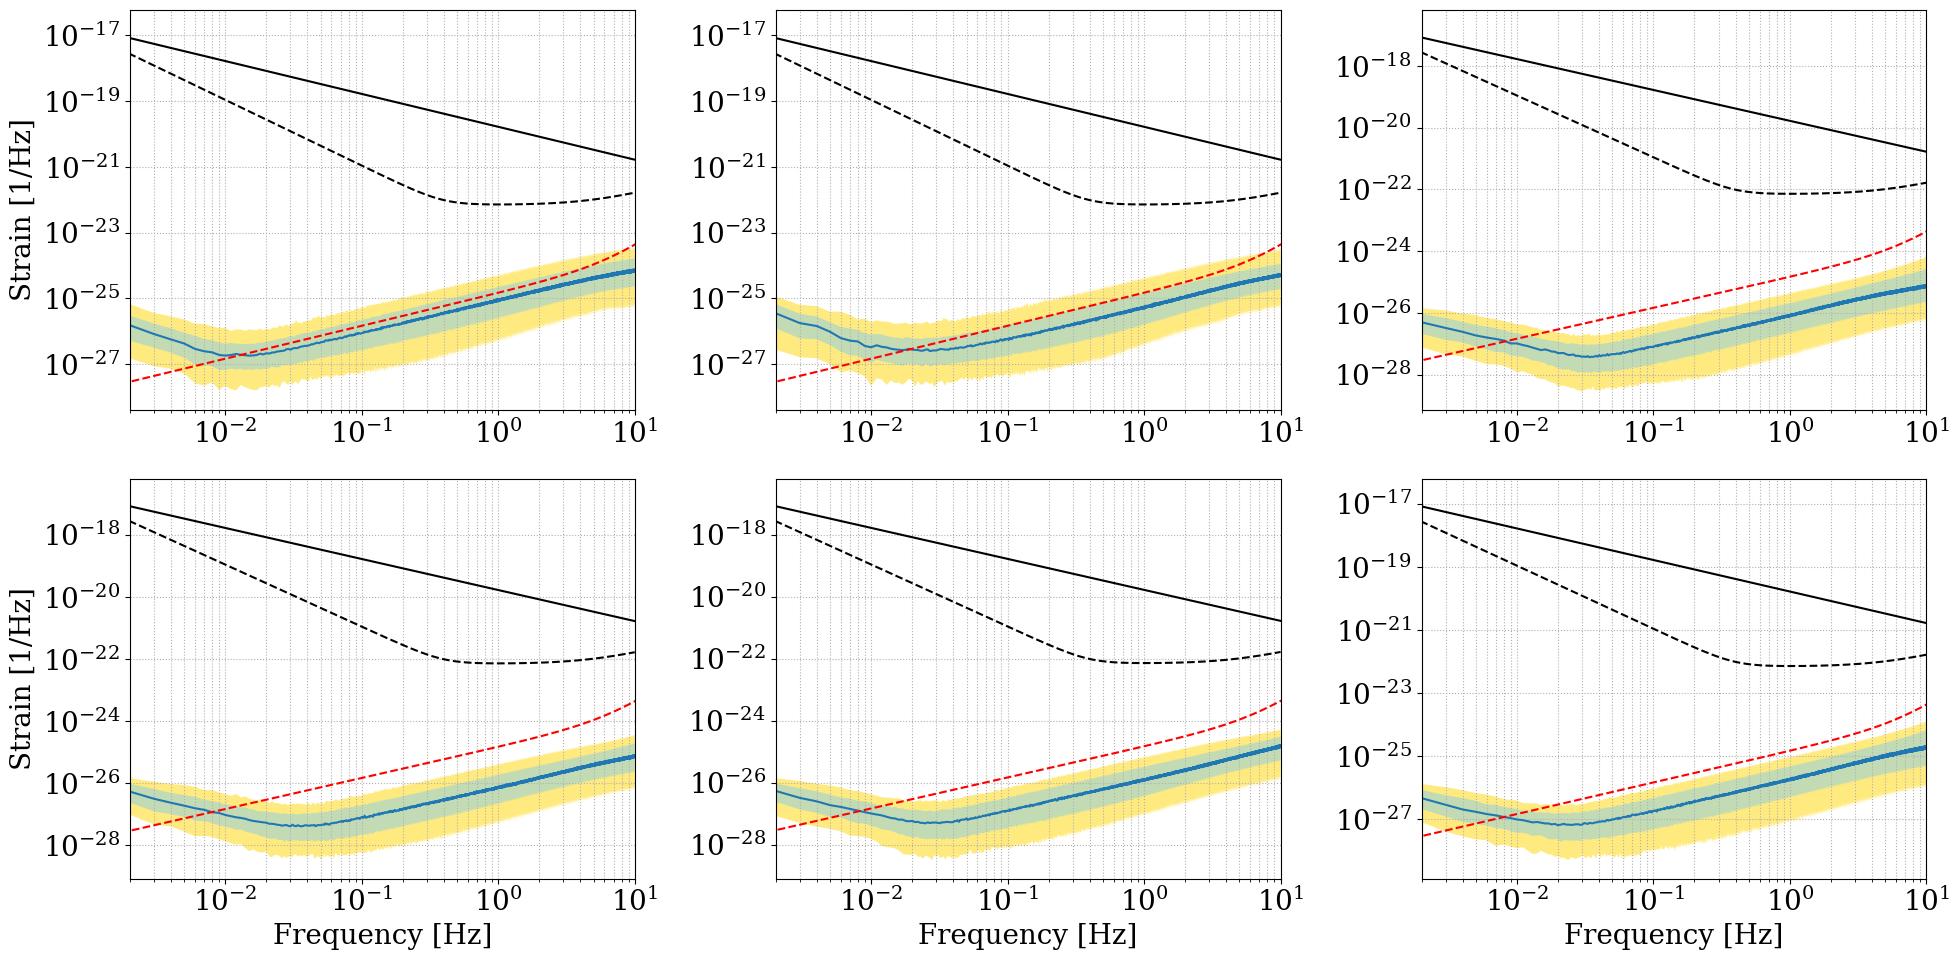

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()

ax1 = axes[0]
ax2 = axes[1]
ax3 = axes[2]
ax4 = axes[3]
ax5 = axes[4]
ax6 = axes[5]

#ax1.fill_between(Freqbfsr, fnoise_dis(res_fnoise1)[0], fnoise_dis(res_fnoise1)[6], facecolor='olive', alpha=0.5)
ax1.fill_between(Freqbfsr, fnoise1_2u, fnoise1_2l, facecolor='gold', alpha=0.5)
ax1.fill_between(Freqbfsr, fnoise1_1u, fnoise1_1l, facecolor='skyblue', alpha=0.5)
ax1.loglog(Freqbfsr, fnoise1_median, label='Simulated median')
ax1.loglog(Freqbfsr, fnoise(Freqbfsr), 'k', label="Frequency noise")
ax1.loglog(Freqbfsr, BLFPI(Freqbfsr), 'k--', label='BLFPI sensitivity')
ax1.loglog(f, da_opt*fnoise(f), 'r--', label='Analytical')

#ax2.fill_between(Freqbfsr, fnoise_dis(res_fnoise2)[0], fnoise_dis(res_fnoise2)[6], facecolor='olive', alpha=0.5, label="99.7% confidence level")
ax2.fill_between(Freqbfsr, fnoise2_2u, fnoise2_2l, facecolor='gold', alpha=0.5, label="95% confidence level")
ax2.fill_between(Freqbfsr, fnoise2_1u, fnoise2_1l, facecolor='skyblue', alpha=0.5, label="68% confidence level")
ax2.loglog(Freqbfsr, fnoise2_median, label='Simulated median')
ax2.loglog(Freqbfsr, fnoise(Freqbfsr), 'k', label="Frequency noise")
ax2.loglog(Freqbfsr, BLFPI(Freqbfsr), 'k--')
ax2.loglog(f, da_opt*fnoise(f), 'r--', label='Analytical')

#ax3.fill_between(Freqbfsr, fnoise_dis(res_fnoise3)[0], fnoise_dis(res_fnoise3)[6], facecolor='olive', alpha=0.5, label="99.7% confidence level")
ax3.fill_between(Freqbfsr, fnoise3_2u, fnoise3_2l, facecolor='gold', alpha=0.5, label="95% confidence level")
ax3.fill_between(Freqbfsr, fnoise3_1u, fnoise3_1l, facecolor='skyblue', alpha=0.5, label="68% confidence level")
ax3.loglog(Freqbfsr, fnoise3_median, label='Simulated median')
ax3.loglog(Freqbfsr, fnoise(Freqbfsr), 'k', label="Frequency noise")
ax3.loglog(Freqbfsr, BLFPI(Freqbfsr), 'k--')
ax3.loglog(f, da_opt*fnoise(f), 'r--', label='Analytical')

#ax4.fill_between(Freqbfsr, fnoise_dis(res_fnoise4)[0], fnoise_dis(res_fnoise4)[6], facecolor='olive', alpha=0.5, label="99.7% confidence level")
ax4.fill_between(Freqbfsr, fnoise4_2u, fnoise4_2l, facecolor='gold', alpha=0.5, label="95% confidence level")
ax4.fill_between(Freqbfsr, fnoise4_1u, fnoise4_1l, facecolor='skyblue', alpha=0.5, label="68% confidence level")
ax4.loglog(Freqbfsr, fnoise4_median, label='Simulated median')
ax4.loglog(Freqbfsr, fnoise(Freqbfsr), 'k', label="Frequency noise")
ax4.loglog(Freqbfsr, BLFPI(Freqbfsr), 'k--')
ax4.loglog(f, da_opt*fnoise(f), 'r--', label='Analytical')

#ax5.fill_between(Freqbfsr, fnoise_dis(res_fnoise5)[0], fnoise_dis(res_fnoise5)[6], facecolor='olive', alpha=0.5, label="99.7% confidence level")
ax5.fill_between(Freqbfsr, fnoise5_2u, fnoise5_2l, facecolor='gold', alpha=0.5, label="95% confidence level")
ax5.fill_between(Freqbfsr, fnoise5_1u, fnoise5_1l, facecolor='skyblue', alpha=0.5, label="68% confidence level")
ax5.loglog(Freqbfsr, fnoise5_median, label='Simulated median')
ax5.loglog(Freqbfsr, fnoise(Freqbfsr), 'k', label="Frequency noise")
ax5.loglog(Freqbfsr, BLFPI(Freqbfsr), 'k--')
ax5.loglog(f, da_opt*fnoise(f), 'r--', label='Analytical')

#ax6.fill_between(Freqbfsr, fnoise_dis(res_fnoise6)[0], fnoise_dis(res_fnoise6)[6], facecolor='olive', alpha=0.5, label="99.7% confidence level")
ax6.fill_between(Freqbfsr, fnoise6_2u, fnoise6_2l, facecolor='gold', alpha=0.5, label="95% confidence level")
ax6.fill_between(Freqbfsr, fnoise6_1u, fnoise6_1l, facecolor='skyblue', alpha=0.5, label="68% confidence level")
ax6.loglog(Freqbfsr, fnoise6_median, label='Simulated median')
ax6.loglog(Freqbfsr, fnoise(Freqbfsr), 'k', label="Frequency noise")
ax6.loglog(Freqbfsr, BLFPI(Freqbfsr), 'k--')
ax6.loglog(f, da_opt*fnoise(f), 'r--', label='Analytical')

ax1.grid(which="both", linestyle=":")
ax2.grid(which="both", linestyle=":")
ax3.grid(which="both", linestyle=":")
ax4.grid(which="both", linestyle=":")
ax5.grid(which="both", linestyle=":")
ax6.grid(which="both", linestyle=":")

#ax1.legend(loc='upper right')
ax4.set_xlabel("Frequency [Hz]")
ax5.set_xlabel("Frequency [Hz]")
ax6.set_xlabel("Frequency [Hz]")
ax1.set_ylabel("Strain [1/Hz]")
ax4.set_ylabel("Strain [1/Hz]")
#ax5.set_ylabel("Strain [1/Hz]")
ax1.set_xlim([2e-3, 10])
ax2.set_xlim([2e-3, 10])
ax3.set_xlim([2e-3, 10])
ax4.set_xlim([2e-3, 10])
ax5.set_xlim([2e-3, 10])
ax6.set_xlim([2e-3, 10])

plt.tight_layout()